# Adversarial Autoencoder (AAE) Encoder Training

Defines and trains an AAE encoder/decoder stack over the cleaned features. The AAE replaces the KL divergence term in the VAE with an adversarial loss: a discriminator tries to distinguish latent vectors from the encoder vs. samples from the prior (standard normal), while the encoder tries to fool the discriminator.

> Built on top of `02_encoder_training.ipynb` (VAE).

In [16]:
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import plotly.express as px
%matplotlib inline

## Data Loading & Preprocessing

Same pipeline as the VAE notebook.

In [17]:
path = '../../data/cleaned_songs_with_groups.csv'
songs_df = pd.read_csv(path)

X_train_embedding, X_test_embedding, y_train_embedding, y_test_embedding = train_test_split(
    songs_df.drop(columns=['genre_group']), songs_df['genre_group'],
    test_size=0.2, random_state=42, stratify=songs_df['genre_group']
)

ohe = OneHotEncoder()
scaler = StandardScaler()

X_train_embedding_num = X_train_embedding.drop(columns=['key', 'mode'])
X_test_embedding_num = X_test_embedding.drop(columns=['key', 'mode'])

train_key = ohe.fit_transform(X_train_embedding['key'].values.reshape(-1, 1)).toarray()
test_key = ohe.transform(X_test_embedding['key'].values.reshape(-1, 1)).toarray()
train_mode = X_train_embedding['mode'].values.reshape(-1, 1)
test_mode = X_test_embedding['mode'].values.reshape(-1, 1)

X_train_embedding_cat = np.concatenate((train_key, train_mode), axis=1)
X_test_embedding_cat = np.concatenate((test_key, test_mode), axis=1)

X_train_embedding_num = scaler.fit_transform(X_train_embedding_num)
X_test_embedding_num = scaler.transform(X_test_embedding_num)

X_train_embedding = np.concatenate((X_train_embedding_num, X_train_embedding_cat), axis=1)
X_test_embedding = np.concatenate((X_test_embedding_num, X_test_embedding_cat), axis=1)

# Encode genre labels for supervised classification loss
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train_embedding)
y_test_encoded = label_encoder.transform(y_test_embedding)
num_genres = len(label_encoder.classes_)

print(f"Train shape: {X_train_embedding.shape}, Test shape: {X_test_embedding.shape}")
print(f"Num genres: {num_genres}")

Train shape: (25760, 24), Test shape: (6440, 24)
Num genres: 26


## AAE Architecture

**Encoder & Decoder**: Same as VAE (input_dim -> 19 -> 15 -> latent_dim).

**Discriminator**: Takes latent vectors (real from prior N(0,I) or fake from encoder) and outputs probability of being real. Trained to distinguish; encoder is trained to fool it.

In [18]:
latent_dim = 12
input_dim = X_train_embedding.shape[1]

class MixtureGaussianPrior:
    """
    Mixture-of-Gaussians prior p(z) = sum_k pi_k N(mu_k, sigma^2 I)
    Designed to be smooth by using moderate mean spread (alpha) and
    sufficiently large sigma to create overlap (no big gaps).
    """
    def __init__(self, K, latent_dim, alpha=1.5, sigma=1.0, device="cpu", learnable_means=False):
        self.K = K
        self.latent_dim = latent_dim
        self.alpha = alpha
        self.sigma = sigma
        self.device = device

        # Initialize component means near the origin (controls separation)
        mus = torch.randn(K, latent_dim, device=device) * alpha  # spread controlled by alpha

        if learnable_means:
            self.mus = torch.nn.Parameter(mus)
        else:
            self.mus = mus  # fixed means

        # Uniform mixture weights (can change later)
        self.pi = torch.ones(K, device=device) / K

    def sample_conditional(self, y):
        mu = self.mus[y]  # (batch, latent_dim)
        eps = torch.randn_like(mu)
        return mu + self.sigma * eps

    def sample(self, batch_size):
        # Sample mixture component indices
        k = torch.multinomial(self.pi, batch_size, replacement=True)  # (batch,)
        mu = self.mus[k]  # (batch, latent_dim)
        eps = torch.randn(batch_size, self.latent_dim, device=self.device)
        z = mu + self.sigma * eps
        return z


def sampling(z_mean, z_log_var):
    """Reparameterization trick: z = z_mean + exp(z_log_var) * epsilon."""
    epsilon = torch.randn_like(z_mean)
    return z_mean + torch.exp(z_log_var) * epsilon


class Encoder(nn.Module):
    """input_dim -> 19 (ReLU) -> 15 (ReLU) -> z_mean, z_log_var"""

    def __init__(self, input_dim, latent_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 19)
        self.fc2 = nn.Linear(19, 15)
        self.z_mean = nn.Linear(15, latent_dim)
        self.z_log_var = nn.Linear(15, latent_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.z_mean(x), self.z_log_var(x)


class Decoder(nn.Module):
    """latent_dim -> 15 (ReLU) -> 19 (ReLU) -> input_dim (tanh)"""

    def __init__(self, latent_dim, input_dim):
        super().__init__()
        self.fc1 = nn.Linear(latent_dim, 15)
        self.fc2 = nn.Linear(15, 19)
        self.out = nn.Linear(19, input_dim)

    def forward(self, z):
        x = F.relu(self.fc1(z))
        x = F.relu(self.fc2(x))
        return torch.tanh(self.out(x))


class Discriminator(nn.Module):
    """
    Discriminator for AAE: classifies latent vectors as real (from prior) or fake (from encoder).
    latent_dim -> 64 (LeakyReLU) -> 32 (LeakyReLU) -> 1 (sigmoid)
    """

    def __init__(self, latent_dim, hidden_dims=(64, 32)):
        super().__init__()
        layers = []
        prev = latent_dim
        for h in hidden_dims:
            layers.extend([nn.Linear(prev, h), nn.LeakyReLU(0.2)])
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return torch.sigmoid(self.net(z))


class GenreClassifier(nn.Module):
    """Predicts genre from latent z. Used as auxiliary loss to improve clustering."""
    def __init__(self, latent_dim, num_genres):
        super().__init__()
        self.fc = nn.Linear(latent_dim, num_genres)

    def forward(self, z):
        return self.fc(z)


class AAE(nn.Module):
    """Adversarial Autoencoder: encoder + decoder (same forward as VAE)."""

    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x):
        z_mean, z_log_var = self.encoder(x)
        z = sampling(z_mean, z_log_var)
        reconstruction = self.decoder(z)
        return reconstruction, z_mean, z_log_var, z

## Loss Functions & Training Steps

In [ ]:
def reconstruction_loss(data, reconstruction):
    """MSE reconstruction loss (same as VAE)."""
    return F.mse_loss(reconstruction, data, reduction='sum') / data.size(0)


def train_reconstruction(aae, classifier, optimizer_ae, batch_x, batch_y, device, cls_weight=1.0):
    """Update encoder + decoder with reconstruction loss + genre classification loss."""
    aae.train()
    classifier.train()
    batch_x = batch_x.to(device)
    batch_y = batch_y.to(device).long()
    reconstruction, z_mean, z_log_var, z = aae(batch_x)
    recon_loss = reconstruction_loss(batch_x, reconstruction)
    logits = classifier(z)
    cls_loss = F.cross_entropy(logits, batch_y)
    total_loss = recon_loss + cls_weight * cls_loss
    optimizer_ae.zero_grad()
    total_loss.backward()
    optimizer_ae.step()
    return float(recon_loss.item()), float(cls_loss.item())


def train_discriminator(discriminator, optimizer_d, batch_z, batch_y, device, prior):
    discriminator.train()
    batch_y = batch_y.to(device).long()

    real_z = prior.sample_conditional(batch_y)    # <-- genre-conditioned real
    fake_z = batch_z.detach()

    real_pred = discriminator(real_z)
    fake_pred = discriminator(fake_z)

    loss_real = F.binary_cross_entropy(real_pred, torch.ones_like(real_pred))
    loss_fake = F.binary_cross_entropy(fake_pred, torch.zeros_like(fake_pred))
    d_loss = loss_real + loss_fake

    optimizer_d.zero_grad()
    d_loss.backward()
    optimizer_d.step()
    return float(d_loss.item())


def train_generator(aae, discriminator, optimizer_ae, batch_x, device):
    """Update encoder to fool discriminator: max log D(encoder(x))."""
    aae.train()
    discriminator.eval()  # Don't update discriminator
    batch_x = batch_x.to(device)

    _, _, _, z = aae(batch_x)
    pred = discriminator(z)

    # Generator wants D(z) to be 1 (fool discriminator)
    g_loss = F.binary_cross_entropy(pred, torch.ones_like(pred))

    optimizer_ae.zero_grad()
    g_loss.backward()
    optimizer_ae.step()
    return float(g_loss.item())

## Training Loop

Each epoch:
1. **Reconstruction phase**: Update encoder + decoder with reconstruction loss.
2. **Regularization phase**: Update discriminator, then update encoder (generator) to fool it.

In [20]:
device = "cuda" if torch.cuda.is_available() else "cpu"

encoder = Encoder(input_dim=input_dim, latent_dim=latent_dim)
decoder = Decoder(latent_dim=latent_dim, input_dim=input_dim)
discriminator = Discriminator(latent_dim=latent_dim)
classifier = GenreClassifier(latent_dim=latent_dim, num_genres=num_genres)
aae = AAE(encoder, decoder)

K = num_genres  # or choose 8, 10, 16, etc.
prior = MixtureGaussianPrior(
    K=K,
    latent_dim=latent_dim,
    alpha=1.5,      # controls cluster separation
    sigma=1.0,      # controls overlap/smoothness
    device=device,
    learnable_means=False
)

aae.to(device)
discriminator.to(device)
classifier.to(device)

X_train_tensor = torch.from_numpy(X_train_embedding).float()
y_train_tensor = torch.from_numpy(y_train_encoded).long()
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# AE optimizer: encoder + decoder + classifier (for reconstruction + classification)
optimizer_ae = torch.optim.Adam(
    list(encoder.parameters()) + list(decoder.parameters()) + list(classifier.parameters()),
    lr=1e-3
)
optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=1e-3)

num_epochs = 100
cls_weight = 1.0  # Weight for genre classification loss
recon_losses = []
cls_losses = []
d_losses = []
g_losses = []

In [21]:
for epoch in range(num_epochs):
    epoch_recon = 0.0
    epoch_cls = 0.0
    epoch_d = 0.0
    epoch_g = 0.0
    count = 0

    for batch_x, batch_y in train_loader:
        batch_size = batch_x.size(0)

        # 1. Reconstruction phase (recon + genre classification)
        recon, cls = train_reconstruction(aae, classifier, optimizer_ae, batch_x, batch_y, device, cls_weight)
        epoch_recon += recon
        epoch_cls += cls

        # 2. Get latent z for discriminator
        with torch.no_grad():
            _, _, _, z = aae(batch_x.to(device))

        # 3. Discriminator phase
        d_loss = train_discriminator(discriminator, optimizer_d, z, batch_y, device, prior)
        ##d_loss = train_discriminator(discriminator, optimizer_d, z, batch_size, device)
        epoch_d += d_loss

        # 4. Generator (encoder) phase
        g_loss = train_generator(aae, discriminator, optimizer_ae, batch_x, device)
        epoch_g += g_loss

        count += 1

    n = len(train_loader)
    recon_losses.append(epoch_recon / n)
    cls_losses.append(epoch_cls / n)
    d_losses.append(epoch_d / n)
    g_losses.append(epoch_g / n)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:03d} | recon={recon_losses[-1]:.4f} | cls={cls_losses[-1]:.4f} | D={d_losses[-1]:.4f} | G={g_losses[-1]:.4f}")

Epoch 001 | recon=8.7350 | cls=2.6476 | D=0.8231 | G=1.5132
Epoch 010 | recon=3.9222 | cls=2.1104 | D=1.1125 | G=1.1544
Epoch 020 | recon=3.5356 | cls=2.0777 | D=1.0759 | G=1.0755
Epoch 030 | recon=3.3548 | cls=2.0683 | D=1.0911 | G=1.0625
Epoch 040 | recon=3.3543 | cls=2.0637 | D=1.0558 | G=1.1197
Epoch 050 | recon=3.2992 | cls=2.0657 | D=1.0385 | G=1.1407
Epoch 060 | recon=3.2778 | cls=2.0824 | D=1.1019 | G=1.1068
Epoch 070 | recon=3.2489 | cls=2.0759 | D=1.1239 | G=1.0458
Epoch 080 | recon=3.2217 | cls=2.0635 | D=1.1180 | G=1.0135
Epoch 090 | recon=3.2217 | cls=2.0776 | D=1.0949 | G=1.0593
Epoch 100 | recon=3.2218 | cls=2.0704 | D=1.1173 | G=1.0445


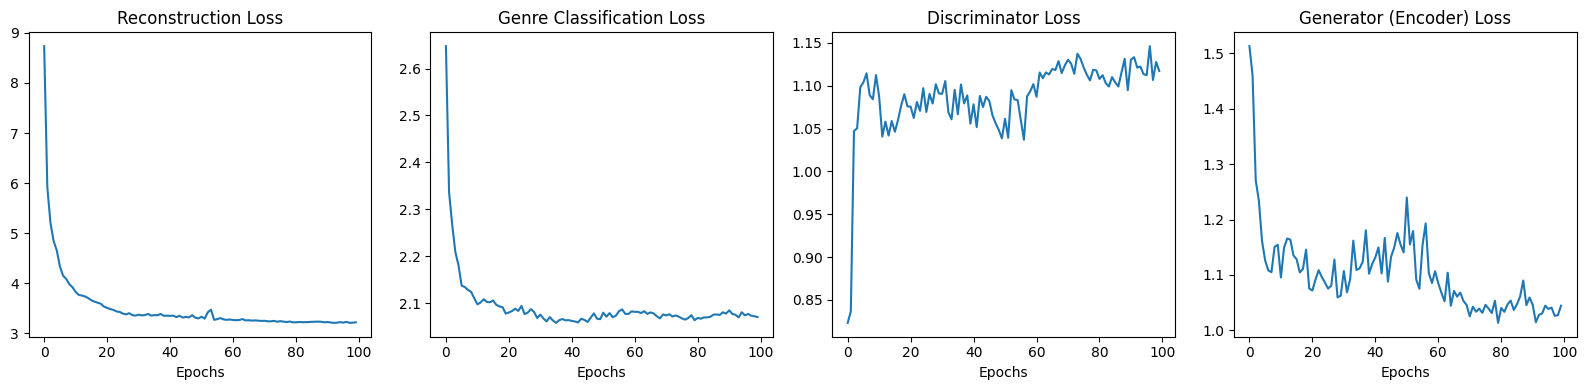

In [22]:
plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1)
plt.plot(recon_losses)
plt.title('Reconstruction Loss')
plt.xlabel('Epochs')

plt.subplot(1, 4, 2)
plt.plot(cls_losses)
plt.title('Genre Classification Loss')
plt.xlabel('Epochs')

plt.subplot(1, 4, 3)
plt.plot(d_losses)
plt.title('Discriminator Loss')
plt.xlabel('Epochs')

plt.subplot(1, 4, 4)
plt.plot(g_losses)
plt.title('Generator (Encoder) Loss')
plt.xlabel('Epochs')
plt.tight_layout()
plt.show()

In [23]:
import torch
# Trying to visualize latent space using UMAP
from umap import UMAP

encoder.eval()
with torch.no_grad():
    X_train_tensor = torch.from_numpy(X_train_embedding).float().to(device)
    z_mean, z_log_var = encoder(X_train_tensor)
    latent_space = z_mean.cpu().numpy()

umap = UMAP(n_neighbors=20, min_dist=0.1, random_state=42)
z_umap = umap.fit_transform(latent_space)

df_umap = pd.DataFrame({
    "u0": z_umap[:, 0],
    "u1": z_umap[:, 1],
    "genre_group": y_train_embedding
})
fig = px.scatter(df_umap, x="u0", y="u1", color="genre_group", title="UMAP Latent Space")
fig.show()

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(latent_space)

# Convert the data to a pandas DataFrame
df = pd.DataFrame({
    'pca0': X_train_pca[:, 0],
    'pca1': X_train_pca[:, 1],
    'genre_group': y_train_embedding
})

#Original code line: df = pd.DataFrame({'pca0': X_train_pca[:, 0], 'pca1': X_train_pca[:, 1], 'genre_group': y_train_embedding})

# Create a scatter plot using Plotly
fig = px.scatter(df, x='pca0', y='pca1', color='genre_group')

# Add labels and adjust the layout
fig.update_layout(
    title='PCA Latent Space Visualization',
    xaxis_title='pca0',
    yaxis_title='pca1',
    legend_title='Genre Group'
)

# Display the plot
fig.show()

/Users/lucasmusselman/Documents/GitHub/Capstone_Playlist_Creator/venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



## Save Model

In [ ]:
os.makedirs('../checkpoints', exist_ok=True)
torch.save({
    'encoder': encoder.state_dict(),
    'decoder': decoder.state_dict(),
    'discriminator': discriminator.state_dict(),
    'classifier': classifier.state_dict(),
    'scaler': scaler,
    'ohe': ohe,
    'label_encoder': label_encoder,
    'input_dim': input_dim,
    'latent_dim': latent_dim,
    'num_genres': num_genres,
}, '../checkpoints/aae_encoder.pt')
print('Saved to Model/checkpoints/aae_encoder.pt')